# Letecké nehody v datech

Cílem této případové studie je prozkoumat vývoj evidovaných leteckých nehod, jejich sezónnost a rozdíly mezi provozovateli a typy letadel. Součástí analýzy je také porovnání přežití a návrh vlastní segmentace nehod.

Notebook postupně představuje kontrolu dat, jejich přípravu a odpovědi na jednotlivé otázky zadání.

## 1. Načtení dat

Načítáme dataset. Zdrojová data uchováváme samostatně a pro další práci vytváříme jejich kopii.

In [26]:
import io
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

uploaded = files.upload()

filename = "Airplane_Crashes_and_Casualties_Case_Study.csv"

df_raw = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    sep=";",
    encoding="utf-8"
)

# Původní data uchováváme; další kroky provádíme na kopii.
df = df_raw.copy()

print(f"Počet záznamů: {len(df):,}".replace(",", " "))
print(f"Počet sloupců: {df.shape[1]}")

display(df.head())

Saving Airplane_Crashes_and_Casualties_Case_Study.csv to Airplane_Crashes_and_Casualties_Case_Study.csv
Počet záznamů: 5 268
Počet sloupců: 13


,Date,Time,Location,Operator,Flight #,Route,Type,Registration,cn/In,Aboard,Fatalities,Ground,Summary
0,17.09.1908,17:18,"Fort Myer, Virginia",Military - U.S. Army,NaN,Demonstration,Wright Flyer III,NaN,1,2.0,1.0,0.0,"During a demonstration flight, a U.S. Army fly..."
1,12.07.1912,6:30,"AtlantiCity, New Jersey",Military - U.S. Navy,NaN,Test flight,Dirigible,NaN,NaN,5.0,5.0,0.0,First U.S. dirigible Akron exploded just offsh...
2,06.08.1913,NaN,"Victoria, British Columbia, Canada",Private,-,NaN,Curtiss seaplane,NaN,NaN,1.0,1.0,0.0,The first fatal airplane accident in Canada oc...
3,09.09.1913,18:30,Over the North Sea,Military - German Navy,NaN,NaN,Zeppelin L-1 (airship),NaN,NaN,20.0,14.0,0.0,The airship flew into a thunderstorm and encou...
4,17.10.1913,10:30,"Near Johannisthal, Germany",Military - German Navy,NaN,NaN,Zeppelin L-2 (airship),NaN,NaN,30.0,30.0,0.0,Hydrogen gas which was being vented was sucked...


## 2. Základní kontrola dat

Před analýzou ověřujeme datové typy, chybějící hodnoty, plně shodné řádky a časový rozsah datasetu.

U počtů osob kontrolujeme záporné hodnoty, počet obětí převyšující počet osob na palubě a nulový počet osob na palubě. Tyto kontroly pomohou určit, které záznamy lze použít pro výpočet přežití.

In [27]:
# Přehled struktury a chybějících hodnot původního datasetu.
overview = pd.DataFrame({
    "Datový typ": df_raw.dtypes.astype(str),
    "Chybějící hodnoty": df_raw.isna().sum(),
    "Chybějící hodnoty (%)": (
        df_raw.isna().mean() * 100
    ).round(1),
    "Počet různých hodnot": df_raw.nunique()
})

display(overview)

# Pomocné převody pro kontrolu; původní data neměníme.
dates = pd.to_datetime(
    df_raw["Date"],
    format="%d.%m.%Y",
    errors="coerce"
)

numeric_columns = ["Aboard", "Fatalities", "Ground"]

counts = df_raw[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

invalid_numbers = (
    df_raw[numeric_columns].notna() & counts.isna()
).sum().sum()

checks = pd.Series({
    "Úplně shodné řádky":
        int(df_raw.duplicated().sum()),
    "Chybějící nebo neplatná data nehod":
        int(dates.isna().sum()),
    "Neplatné číselné hodnoty":
        int(invalid_numbers),
    "Řádky se záporným počtem osob nebo obětí":
        int(counts.lt(0).any(axis=1).sum()),
    "Řádky s více oběťmi než osobami na palubě":
        int(counts["Fatalities"].gt(counts["Aboard"]).sum()),
    "Řádky s nulovým počtem osob na palubě":
        int(counts["Aboard"].eq(0).sum())
}, name="Počet")

display(checks.to_frame())

print()

print(
    "Časový rozsah:",
    dates.min().strftime("%d.%m.%Y"),
    "až",
    dates.max().strftime("%d.%m.%Y")
)

# Záznamy s nulovým počtem osob na palubě.
display(
    df_raw.loc[
        counts["Aboard"].eq(0),
        ["Date", "Operator", "Type", "Aboard", "Fatalities", "Ground"]
    ]
)

,Datový typ,Chybějící hodnoty,Chybějící hodnoty (%),Počet různých hodnot
Date,object,0,0.0,4753
Time,object,2219,42.1,999
Location,object,20,0.4,4303
Operator,object,18,0.3,2476
Flight #,object,4199,79.7,713
Route,object,1707,32.4,3243
Type,object,27,0.5,2446
Registration,object,335,6.4,4903
cn/In,object,1228,23.3,3638
Aboard,float64,22,0.4,239


,Počet
Úplně shodné řádky,0
Chybějící nebo neplatná data nehod,0
Neplatné číselné hodnoty,0
Řádky se záporným počtem osob nebo obětí,0
Řádky s více oběťmi než osobami na palubě,0
Řádky s nulovým počtem osob na palubě,2



Časový rozsah: 17.09.1908 až 08.06.2009


,Date,Operator,Type,Aboard,Fatalities,Ground
3307,22.09.1981,Military - Turkish Air Force,Northrop F-5A,0.0,0.0,40.0
3611,27.03.1986,Military - French Air Force,Sepecat Jaguar A,0.0,0.0,35.0


### Výsledky kontroly

Dataset obsahuje 5 268 záznamů a 13 sloupců. Pokrývá období od 17. září 1908 do 8. června 2009. Poslední rok je neúplný, což zohledníme při porovnávání ročních počtů nehod.

Kontrola neodhalila úplně shodné řádky, neplatná data nehod, záporné počty osob ani případy, kdy by počet obětí na palubě převyšoval počet osob na palubě.

Počet osob na palubě chybí u 22 záznamů a počet obětí na palubě u 12 záznamů. Dva záznamy mají nulový počet osob na palubě, tuto informaci si pamatujeme pro pozdější analýzu.

Čas nehody chybí přibližně u 42 % záznamů.

## 3. Příprava dat pro analýzu

Datum nehody převádíme na datový typ datum a odvozujeme rok, měsíc a den v týdnu.

Z počtu osob a obětí na palubě odvozujeme počet přeživších, míru přežití a míru úmrtnosti. Výpočty provádíme pouze u záznamů se známými, nezápornými počty, kde počet obětí nepřevyšuje počet osob na palubě. Pro výpočet podílů navíc požadujeme kladný počet osob na palubě.

Oběti na zemi do míry přežití osob na palubě nezahrnujeme. Chybějící údaje ponecháváme jako neznámé a záznamy zachováváme.

In [28]:
# Převod datových typů.
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d.%m.%Y",
    errors="coerce"
)

for column in ["Aboard", "Fatalities", "Ground"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Časové atributy.
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.dayofweek + 1  # Pondělí = 1.

month_names = {
    1: "Leden", 2: "Únor", 3: "Březen", 4: "Duben",
    5: "Květen", 6: "Červen", 7: "Červenec", 8: "Srpen",
    9: "Září", 10: "Říjen", 11: "Listopad", 12: "Prosinec"
}

weekday_names = {
    1: "Pondělí", 2: "Úterý", 3: "Středa", 4: "Čtvrtek",
    5: "Pátek", 6: "Sobota", 7: "Neděle"
}

df["Month_name"] = df["Month"].map(month_names)
df["Weekday_name"] = df["Weekday"].map(weekday_names)

# Platné počty pro výpočet přeživších.
df["Valid_counts"] = (
    df["Aboard"].notna()
    & df["Fatalities"].notna()
    & df["Aboard"].ge(0)
    & df["Fatalities"].ge(0)
    & df["Fatalities"].le(df["Aboard"])
)

# Podíly lze vypočítat jen s kladným počtem osob na palubě.
df["Valid_survival_rate"] = (
    df["Valid_counts"] & df["Aboard"].gt(0)
)

df["Survivors"] = (
    df["Aboard"] - df["Fatalities"]
).where(df["Valid_counts"])

df["Survival_rate"] = (
    df["Survivors"]
    / df["Aboard"].where(df["Valid_survival_rate"])
)

df["Fatality_rate"] = (
    df["Fatalities"]
    / df["Aboard"].where(df["Valid_survival_rate"])
)

print(
    "Záznamy s vypočitatelnou mírou přežití:",
    int(df["Valid_survival_rate"].sum()),
    "z",
    len(df)
)

# Procentní formát je pouze způsob zobrazení.
display(
    df[[
        "Date", "Year", "Month_name", "Weekday_name",
        "Aboard", "Fatalities", "Survivors",
        "Survival_rate", "Fatality_rate"
    ]]
    .head()
    .style.format({
        "Survival_rate": "{:.1%}",
        "Fatality_rate": "{:.1%}"
    }, na_rep="Neznámé")
)

Záznamy s vypočitatelnou mírou přežití: 5244 z 5268


,Date,Year,Month_name,Weekday_name,Aboard,Fatalities,Survivors,Survival_rate,Fatality_rate
0,1908-09-17 00:00:00,1908,Září,Čtvrtek,2.000000,1.000000,1.000000,50.0%,50.0%
1,1912-07-12 00:00:00,1912,Červenec,Pátek,5.000000,5.000000,0.000000,0.0%,100.0%
2,1913-08-06 00:00:00,1913,Srpen,Středa,1.000000,1.000000,0.000000,0.0%,100.0%
3,1913-09-09 00:00:00,1913,Září,Úterý,20.000000,14.000000,6.000000,30.0%,70.0%
4,1913-10-17 00:00:00,1913,Říjen,Pátek,30.000000,30.000000,0.000000,0.0%,100.0%


# Výsledky

# 4. Vývoj počtu nehod v čase

### Jak se vyvíjel počet evidovaných nehod?

Počet nehod sledujeme po jednotlivých letech. Každý řádek datasetu počítáme jako jeden záznam nehody.

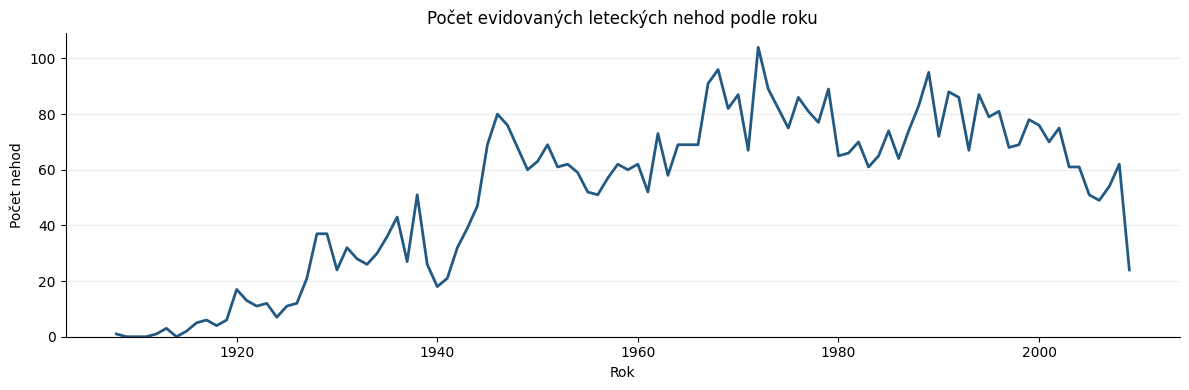



Pět let s nejvyšším počtem nehod


,Rok,Počet evidovaných nehod
0,1972,104
1,1968,96
2,1989,95
3,1967,91
4,1973,89


In [29]:
# Počet nehod v jednotlivých letech.
first_year = int(df["Year"].min())
last_year = int(df["Year"].max())

annual_accidents = (
    df.groupby("Year")
    .size()
    .reindex(range(first_year, last_year + 1), fill_value=0)
    .rename_axis("Year")
    .rename("Accidents")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    annual_accidents["Year"],
    annual_accidents["Accidents"],
    color="#245A81",
    linewidth=2
)

ax.set_title("Počet evidovaných leteckých nehod podle roku")
ax.set_xlabel("Rok")
ax.set_ylabel("Počet nehod")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


print("\n")
print("Pět let s nejvyšším počtem nehod")

display(
    annual_accidents.loc[
        annual_accidents["Year"] < last_year
    ]
    .nlargest(5, "Accidents")
    .rename(columns={
        "Year": "Rok",
        "Accidents": "Počet evidovaných nehod"
    })
    .reset_index(drop=True)
)

### Vývoj počtu evidovaných nehod

V první části sledovaného období počet evidovaných nehod obecně rostl, přestože mezi jednotlivými roky výrazně kolísal. Nejvyšší počet zaznamenáváme v roce 1972, kdy dataset obsahuje 104 nehod. Následují roky 1968 s 96 nehodami a 1989 s 95 nehodami.

Po vrcholu v roce 1972 se neobjevuje souvislý pokles. Počty dále kolísají a další výrazný vrchol nastává v roce 1989. V roce 2008 dataset obsahuje 62 nehod.

Rok 2009 je neúplný a jeho 24 záznamů nelze přímo porovnávat s celými roky. Z grafu také nelze určit, zda se létání stávalo bezpečnějším, chybí údaje o objemu leteckého provozu a úplnosti evidence.

### Mění se počet osob na palubě a míra přežití?

Sledujeme průměrný počet osob na palubě na jednu evidovanou nehodu.

Roční míru přežití počítáme jako součet přeživších dělený součtem osob na palubě ve stejné skupině platných záznamů. Každá osoba tak má ve výpočtu stejnou váhu.

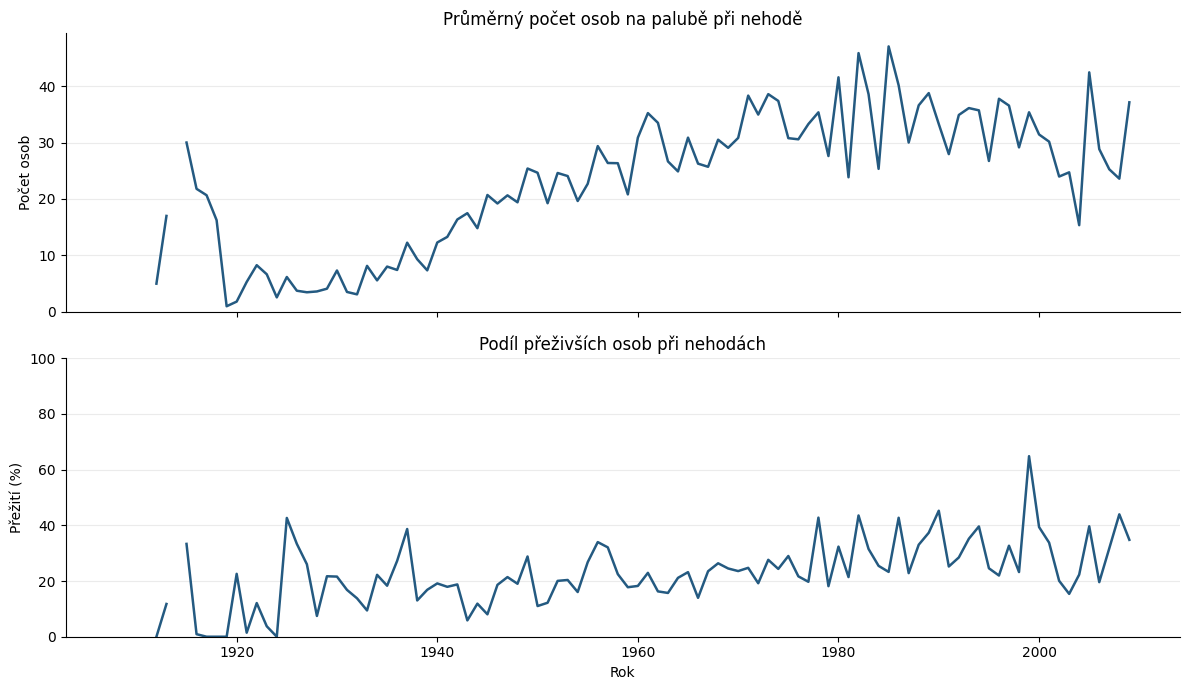

,Počet nehod,Známý počet osob,Průměr osob na palubě,Nehody pro výpočet přežití,Pokrytí výpočtu (%),Míra přežití
Year,,,,,,
2000,76,75,31.4,75,98.7,39.4%
2001,70,70,30.2,70,100.0,33.8%
2002,75,75,24.0,75,100.0,20.1%
2003,61,61,24.7,61,100.0,15.4%
2004,61,61,15.4,61,100.0,22.3%
2005,51,51,42.4,51,100.0,39.6%
2006,49,49,28.8,49,100.0,19.6%
2007,54,54,25.3,54,100.0,31.7%
2008,62,62,23.6,62,100.0,44.0%


In [30]:
# Průměrný počet osob na palubě z dostupných hodnot.
annual_people = df.groupby("Year").agg(
    Accidents=("Date", "size"),
    Known_aboard=("Aboard", "count"),
    Mean_aboard=("Aboard", "mean")
)

# Pro výpočet přežití používáme stejnou skupinu
# platných záznamů v čitateli i jmenovateli.
valid = df.loc[df["Valid_survival_rate"]]

annual_survival = valid.groupby("Year").agg(
    Valid_accidents=("Date", "size"),
    Aboard_valid=("Aboard", "sum"),
    Survivors_valid=("Survivors", "sum"),
    Fatalities_valid=("Fatalities", "sum")
)

annual_survival["Survival_rate"] = (
    annual_survival["Survivors_valid"]
    / annual_survival["Aboard_valid"]
)

annual_survival["Fatality_rate"] = (
    annual_survival["Fatalities_valid"]
    / annual_survival["Aboard_valid"]
)

annual_metrics = annual_people.join(annual_survival)

# Nulu doplňujeme pouze u počtu použitelných záznamů.
# Neznámé míry přežití zůstávají neznámé.
annual_metrics["Valid_accidents"] = (
    annual_metrics["Valid_accidents"].fillna(0).astype(int)
)

annual_metrics["Coverage_pct"] = (
    annual_metrics["Valid_accidents"]
    / annual_metrics["Accidents"] * 100
)

# Doplníme časovou osu. Roky bez záznamů budou v křivkách
# představovat mezery, nikoliv nulovou míru přežití.
annual_metrics = annual_metrics.reindex(
    range(int(df["Year"].min()), int(df["Year"].max()) + 1)
)
annual_metrics.index.name = "Year"

fig, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True
)

plots = [
    (
        "Mean_aboard",
        "Průměrný počet osob na palubě při nehodě",
        "Počet osob",
        1
    ),
    (
        "Survival_rate",
        "Podíl přeživších osob při nehodách",
        "Přežití (%)",
        100
    )
]

for ax, (column, title, ylabel, multiplier) in zip(axes, plots):
    ax.plot(
        annual_metrics.index,
        annual_metrics[column] * multiplier,
        color="#245A81",
        linewidth=1.8
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

axes[1].set_ylim(0, 100)
axes[1].set_xlabel("Rok")

plt.tight_layout()
plt.show()

# Přehled posledních deseti let.
display(
    annual_metrics[[
        "Accidents",
        "Known_aboard",
        "Mean_aboard",
        "Valid_accidents",
        "Coverage_pct",
        "Survival_rate"
    ]]
    .tail(10)
    .rename(columns={
        "Accidents": "Počet nehod",
        "Known_aboard": "Známý počet osob",
        "Mean_aboard": "Průměr osob na palubě",
        "Valid_accidents": "Nehody pro výpočet přežití",
        "Coverage_pct": "Pokrytí výpočtu (%)",
        "Survival_rate": "Míra přežití"
    })
    .style.format({
        "Počet nehod": "{:.0f}",
        "Známý počet osob": "{:.0f}",
        "Průměr osob na palubě": "{:.1f}",
        "Nehody pro výpočet přežití": "{:.0f}",
        "Pokrytí výpočtu (%)": "{:.1f}",
        "Míra přežití": "{:.1%}"
    }, na_rep="Neznámé")
)

### Vývoj počtu osob na palubě

Od přibližně 30. let roste průměrný počet osob na palubě při evidovaných nehodách. V pozdějších desetiletích se roční průměry často pohybují mezi 20 a 40 osobami, přesto výrazně kolísají.

Nejvyšší roční průměr zaznamenáváme v roce 1985: přibližně 47 osob na jednu nehodu.

### Vývoj míry přežití

Roční míra přežití výrazně kolísá. V pozdější části sledovaného období se častěji objevují vyšší hodnoty, ale graf neukazuje souvislé zlepšování.

Výrazným výkyvem je rok 1999, kdy přežilo 64,8 % osob na palubě v použitelných záznamech. V roce 2008 dosáhla míra přežití 44,0 %.

### Interpretace výkyvů

Roční výsledky mohou výrazně ovlivnit jednotlivé nehody s velkým počtem osob. U časných let je navíc evidováno jen málo událostí, takže jejich ukazatele jsou zvlášť citlivé na jednotlivé záznamy. Změny mohou souviset s odlišným zastoupením typů letadel, druhů provozu a okolností nehod.

## 5. Sezónnost nehod

### Jsou nehody častější v některých měsících nebo dnech v týdnu?

Porovnáváme počty evidovaných nehod podle měsíce a dne v týdnu. Pro tuto část neúplný rok 2009 vynecháváme, aby zastoupení pouze části roku neovlivnilo porovnání měsíců.

Roční období nevyhodnocujeme, protože dataset zahrnuje různé části světa a stejný měsíc odpovídá na severní a jižní polokouli odlišnému ročnímu období.

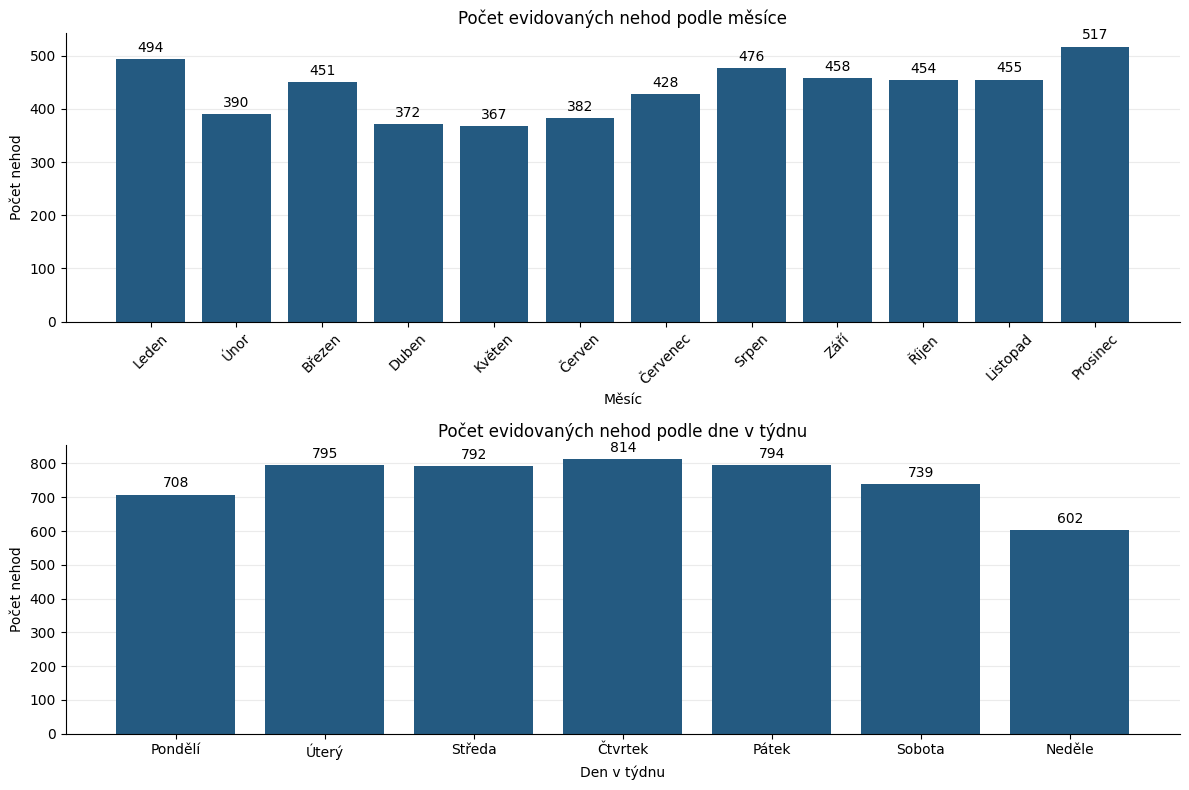

Měsíc,Počet nehod,Podíl nehod
Leden,494,9.4%
Únor,390,7.4%
Březen,451,8.6%
Duben,372,7.1%
Květen,367,7.0%
Červen,382,7.3%
Červenec,428,8.2%
Srpen,476,9.1%
Září,458,8.7%
Říjen,454,8.7%


Den v týdnu,Počet nehod,Podíl nehod
Pondělí,708,13.5%
Úterý,795,15.2%
Středa,792,15.1%
Čtvrtek,814,15.5%
Pátek,794,15.1%
Sobota,739,14.1%
Neděle,602,11.5%


In [31]:
# Pro sezónnost vynecháváme neúplný rok 2009.
seasonal_data = df.loc[df["Year"] <= 2008].copy()

monthly_accidents = (
    seasonal_data.groupby("Month")
    .size()
    .reindex(range(1, 13), fill_value=0)
    .rename_axis("Month")
    .rename("Accidents")
    .reset_index()
)

monthly_accidents["Month_name"] = (
    monthly_accidents["Month"].map(month_names)
)

weekday_accidents = (
    seasonal_data.groupby("Weekday")
    .size()
    .reindex(range(1, 8), fill_value=0)
    .rename_axis("Weekday")
    .rename("Accidents")
    .reset_index()
)

weekday_accidents["Weekday_name"] = (
    weekday_accidents["Weekday"].map(weekday_names)
)

# Podíl na všech nehodách zahrnutých do této části.
monthly_accidents["Share"] = (
    monthly_accidents["Accidents"] / len(seasonal_data)
)

weekday_accidents["Share"] = (
    weekday_accidents["Accidents"] / len(seasonal_data)
)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].bar(
    monthly_accidents["Month_name"],
    monthly_accidents["Accidents"],
    color="#245A81"
)

axes[0].set_title("Počet evidovaných nehod podle měsíce")
axes[0].set_xlabel("Měsíc")
axes[0].tick_params(axis="x", labelrotation=45)

axes[1].bar(
    weekday_accidents["Weekday_name"],
    weekday_accidents["Accidents"],
    color="#245A81"
)

axes[1].set_title("Počet evidovaných nehod podle dne v týdnu")
axes[1].set_xlabel("Den v týdnu")

for ax in axes:
    ax.set_ylabel("Počet nehod")
    ax.set_ylim(bottom=0)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

    # Počet nehod nad každým sloupcem.
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.12)

plt.tight_layout()
plt.show()

# Tabulky zachovávají kalendářní pořadí.
display(
    monthly_accidents[["Month_name", "Accidents", "Share"]]
    .rename(columns={
        "Month_name": "Měsíc",
        "Accidents": "Počet nehod",
        "Share": "Podíl nehod"
    })
    .style.format({"Podíl nehod": "{:.1%}"})
    .hide(axis="index")
)

display(
    weekday_accidents[["Weekday_name", "Accidents", "Share"]]
    .rename(columns={
        "Weekday_name": "Den v týdnu",
        "Accidents": "Počet nehod",
        "Share": "Podíl nehod"
    })
    .style.format({"Podíl nehod": "{:.1%}"})
    .hide(axis="index")
)

In [32]:
for table, name_column, label in [
    (monthly_accidents, "Month_name", "Měsíc"),
    (weekday_accidents, "Weekday_name", "Den")
]:
    maximum = table["Accidents"].max()
    minimum = table["Accidents"].min()

    highest = table.loc[table["Accidents"].eq(maximum)]
    lowest = table.loc[table["Accidents"].eq(minimum)]

    print(f"{label} s nejvyšším počtem nehod:")
    for _, row in highest.iterrows():
        print(
            f"  {row[name_column]}: {row['Accidents']} "
            f"({row['Share']:.1%})"
        )

    print(f"{label} s nejnižším počtem nehod:")
    for _, row in lowest.iterrows():
        print(
            f"  {row[name_column]}: {row['Accidents']} "
            f"({row['Share']:.1%})"
        )

    print()

Měsíc s nejvyšším počtem nehod:
  Prosinec: 517 (9.9%)
Měsíc s nejnižším počtem nehod:
  Květen: 367 (7.0%)

Den s nejvyšším počtem nehod:
  Čtvrtek: 814 (15.5%)
Den s nejnižším počtem nehod:
  Neděle: 602 (11.5%)



### Rozdíly mezi měsíci

Nejvíce evidovaných nehod připadá na prosinec: 517, tedy 9,9 % záznamů zahrnutých do analýzy sezónnosti. Nejméně nehod připadá na květen: 367, tedy 7,0 %. Prosinec tak obsahuje o 150 nehod více než květen.

Vyšší počty pozorujeme také v lednu a srpnu. Rozložení mezi měsíci není rovnoměrné, ale souhrn za celé sledované období ještě neprokazuje, že se stejný vzorec pravidelně opakuje každý rok.

### Rozdíly mezi dny v týdnu

Nejvyšší počet nehod připadá na čtvrtek: 814, tedy 15,5 %. Nejnižší počet připadá na neděli: 602, tedy 11,5 %. Úterý, středa a pátek mají podobné počty, přibližně 790 až 800 nehod.

## 6. Provozovatelé a typy letadel

### Kteří provozovatelé a typy letadel mají nejvíce evidovaných nehod?

Porovnáváme deset nejčastěji zastoupených provozovatelů a deset nejčastějších typů letadel v celém datasetu.

Používáme názvy uvedené ve zdroji. Odstraňujeme pouze mezery na začátku a konci názvu. Různé názvy provozovatelů ani varianty letadel bez dalšího ověření neslučujeme.

Záznamy s neznámým provozovatelem nebo typem letadla ponecháváme v datasetu, ale nezařazujeme je do příslušného žebříčku.

In [33]:
# Nové sloupce pro seskupování; původní názvy zachováváme.
df["Operator_group"] = (
    df["Operator"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

df["Type_group"] = (
    df["Type"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

top_operators = (
    df["Operator_group"]
    .value_counts()
    .head(10)
    .rename_axis("Operator")
    .rename("Accidents")
    .reset_index()
)

top_types = (
    df["Type_group"]
    .value_counts()
    .head(10)
    .rename_axis("Type")
    .rename("Accidents")
    .reset_index()
)

print(
    "Záznamy bez známého provozovatele:",
    int(df["Operator_group"].isna().sum())
)
print(
    "Záznamy bez známého typu letadla:",
    int(df["Type_group"].isna().sum())
)

display(
    top_operators.rename(columns={
        "Operator": "Provozovatel",
        "Accidents": "Počet evidovaných nehod"
    })
)

display(
    top_types.rename(columns={
        "Type": "Typ letadla",
        "Accidents": "Počet evidovaných nehod"
    })
)

Záznamy bez známého provozovatele: 18
Záznamy bez známého typu letadla: 27


,Provozovatel,Počet evidovaných nehod
0,Aeroflot,179
1,Military - U.S. Air Force,176
2,Air France,70
3,Deutsche Lufthansa,65
4,Air Taxi,44
5,China National Aviation Corporation,44
6,United Air Lines,44
7,Military - U.S. Army Air Forces,43
8,Pan American World Airways,41
9,Military - U.S. Navy,36


,Typ letadla,Počet evidovaných nehod
0,Douglas DC-3,334
1,de Havilland Canada DHC-6 Twin Otter 300,81
2,Douglas C-47A,74
3,Douglas C-47,62
4,Douglas DC-4,40
5,Yakovlev YAK-40,37
6,Antonov AN-26,36
7,Junkers JU-52/3m,32
8,Douglas C-47B,29
9,De Havilland DH-4,28


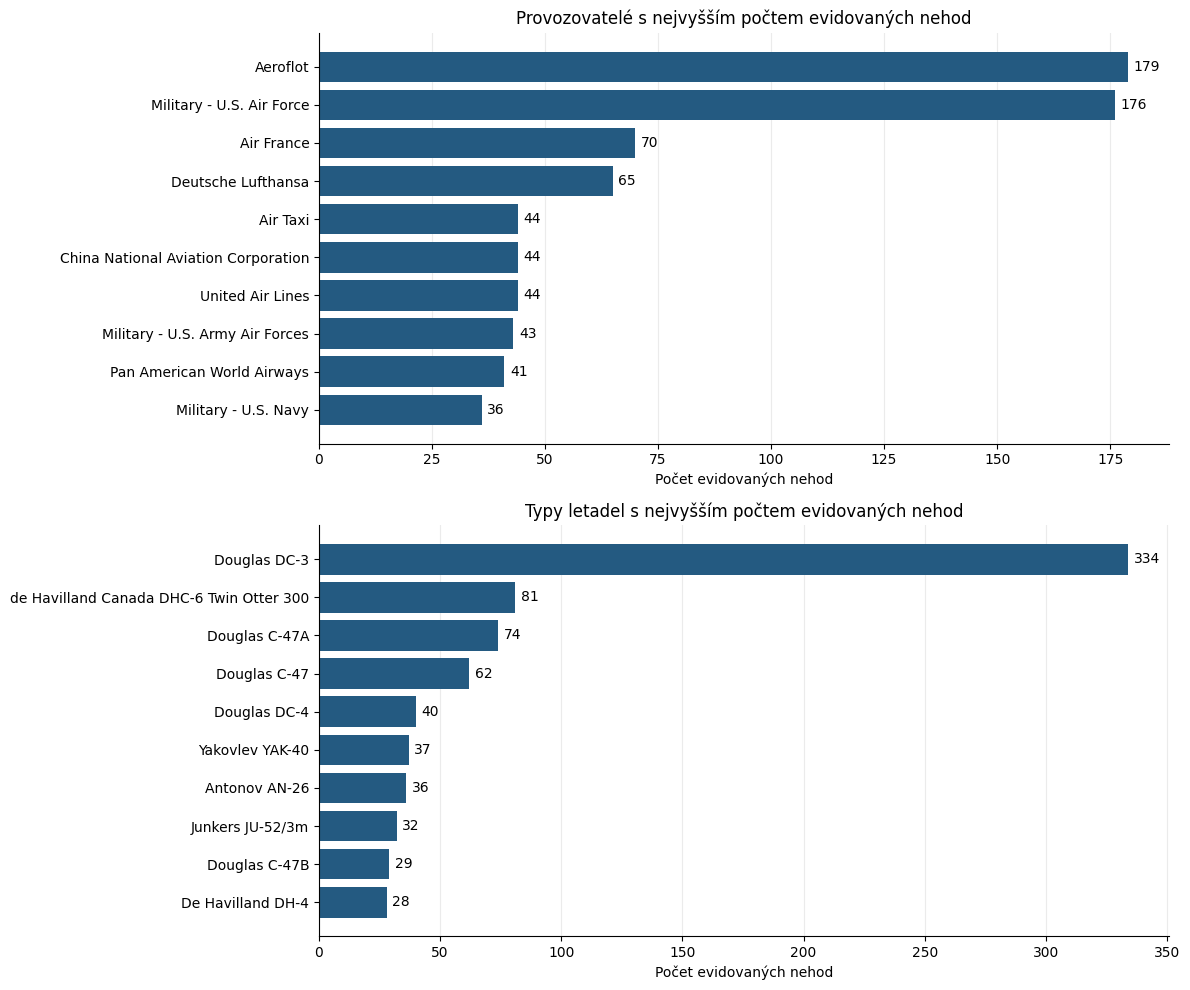

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

plots = [
    (
        top_operators,
        "Operator",
        "Provozovatelé s nejvyšším počtem evidovaných nehod"
    ),
    (
        top_types,
        "Type",
        "Typy letadel s nejvyšším počtem evidovaných nehod"
    )
]

for ax, (table, name_column, title) in zip(axes, plots):
    bars = ax.barh(
        table[name_column],
        table["Accidents"],
        color="#245A81"
    )

    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Počet evidovaných nehod")
    ax.set_xlim(left=0)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.bar_label(bars, padding=4)
    ax.margins(x=0.15)

plt.tight_layout()
plt.show()

### Provozovatelé s nejvyšším počtem nehod

Nejvíce evidovaných nehod je uvedeno pod názvem Aeroflot: 179. Těsně následuje Military - U.S. Air Force se 176 nehodami. Další provozovatelé mají výrazně nižší počty, například Air France 70 a Deutsche Lufthansa 65.

Mezi deseti nejčastěji zastoupenými názvy jsou tři vojenské organizace.

### Typy letadel s nejvyšším počtem nehod

Nejčastěji zastoupeným typem je Douglas DC-3 s 334 nehodami. Následuje de Havilland Canada DHC-6 Twin Otter 300 s 81 nehodami a Douglas C-47A se 74 nehodami.

### Jsou některé typy letadel spojeny s vyšší úmrtností?

Míru úmrtnosti počítáme jako součet obětí na palubě dělený součtem osob na palubě. Oběti na zemi nezahrnujeme.

Porovnáváme typy s alespoň 20 použitelnými záznamy nehod. Jde o zvolenou analytickou hranici, která omezuje vliv velmi malých vzorků; nezaručuje však statistickou spolehlivost výsledků. U každého typu uvádíme také počet nehod a osob, ze kterých výpočet vychází.

In [35]:
# Typ musí být známý a údaje pro výpočet úmrtnosti platné.
valid_types = df.loc[
    df["Valid_survival_rate"]
    & df["Type_group"].notna()
]

type_mortality = valid_types.groupby("Type_group").agg(
    Valid_accidents=("Date", "size"),
    Aboard_valid=("Aboard", "sum"),
    Fatalities_valid=("Fatalities", "sum")
)

type_mortality["Fatality_rate"] = (
    type_mortality["Fatalities_valid"]
    / type_mortality["Aboard_valid"]
)

# Celkový počet evidovaných nehod daného typu,
# včetně těch, u kterých úmrtnost nelze vypočítat.
type_mortality["Total_accidents"] = (
    df["Type_group"].value_counts()
)

type_mortality["Coverage_pct"] = (
    type_mortality["Valid_accidents"]
    / type_mortality["Total_accidents"] * 100
)

minimum_accidents = 20

eligible_types = (
    type_mortality.loc[
        type_mortality["Valid_accidents"] >= minimum_accidents
    ]
    .reset_index()
    .sort_values(
        ["Fatality_rate", "Valid_accidents", "Type_group"],
        ascending=[False, False, True]
    )
)

top_mortality = eligible_types.head(10).copy()

print(
    f"Typy s alespoň {minimum_accidents} použitelnými nehodami:",
    len(eligible_types)
)

display(
    top_mortality[[
        "Type_group",
        "Total_accidents",
        "Valid_accidents",
        "Coverage_pct",
        "Aboard_valid",
        "Fatalities_valid",
        "Fatality_rate"
    ]]
    .rename(columns={
        "Type_group": "Typ letadla",
        "Total_accidents": "Všechny nehody typu",
        "Valid_accidents": "Nehody pro výpočet",
        "Coverage_pct": "Pokrytí výpočtu (%)",
        "Aboard_valid": "Osoby na palubě",
        "Fatalities_valid": "Oběti na palubě",
        "Fatality_rate": "Míra úmrtnosti"
    })
    .style.format({
        "Pokrytí výpočtu (%)": "{:.1f}",
        "Osoby na palubě": "{:.0f}",
        "Oběti na palubě": "{:.0f}",
        "Míra úmrtnosti": "{:.1%}"
    })
    .hide(axis="index")
)

Typy s alespoň 20 použitelnými nehodami: 15


Typ letadla,Všechny nehody typu,Nehody pro výpočet,Pokrytí výpočtu (%),Osoby na palubě,Oběti na palubě,Míra úmrtnosti
De Havilland DH-4,28,27,96.4,28,27,96.4%
Breguet 14,23,23,100.0,42,40,95.2%
Douglas C-47B,29,29,100.0,338,320,94.7%
Douglas C-47,62,61,98.4,1118,1046,93.6%
Douglas C-47A,74,74,100.0,657,609,92.7%
Antonov AN-26,36,36,100.0,1163,1068,91.8%
Douglas C-47-DL,20,20,100.0,325,272,83.7%
Curtiss C-46A,21,21,100.0,225,186,82.7%
Douglas DC-6B,27,27,100.0,1307,1055,80.7%
Douglas DC-3,334,332,99.4,6128,4792,78.2%


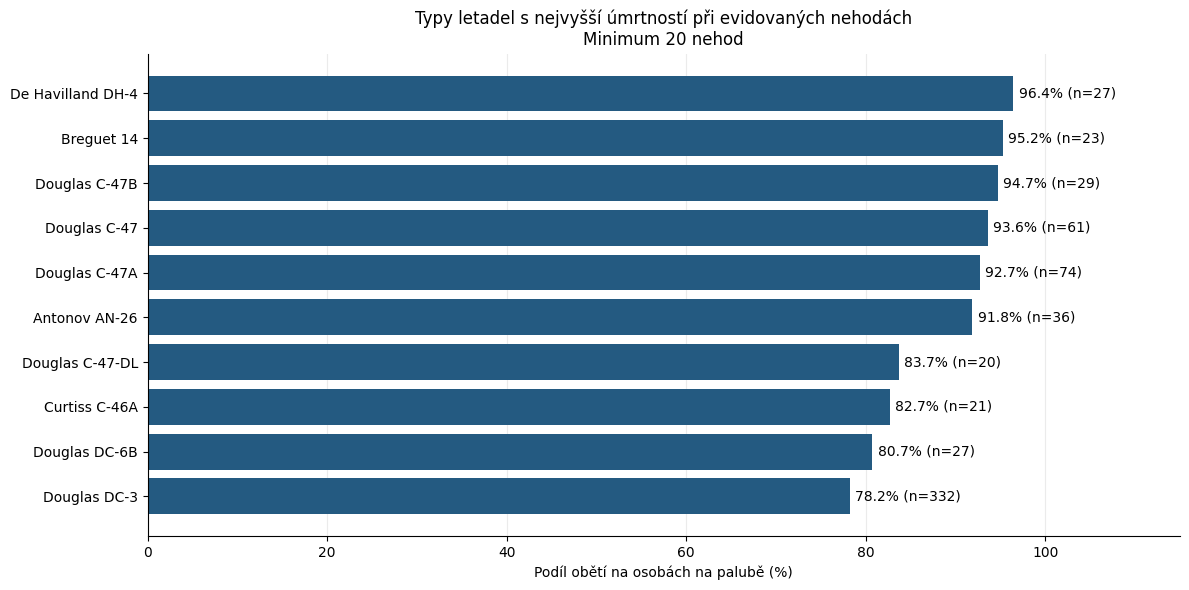

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top_mortality["Type_group"],
    top_mortality["Fatality_rate"] * 100,
    color="#245A81"
)

ax.invert_yaxis()
ax.set_title(
    "Typy letadel s nejvyšší úmrtností při evidovaných nehodách\n"
    f"Minimum {minimum_accidents} nehod"
)
ax.set_xlabel("Podíl obětí na osobách na palubě (%)")
ax.set_xlim(0, 115)
ax.set_xticks(range(0, 101, 20))
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)

labels = [
    f"{rate:.1%} (n={int(count)})"
    for rate, count in zip(
        top_mortality["Fatality_rate"],
        top_mortality["Valid_accidents"]
    )
]

ax.bar_label(bars, labels=labels, padding=4)

plt.tight_layout()
plt.show()

### Rozdíly v úmrtnosti při evidovaných nehodách

Mezi typy s alespoň 20 použitelnými záznamy má nejvyšší podíl obětí De Havilland DH-4: 96,4 %, vypočtených z 27 nehod. Následují Breguet 14 s 95,2 % z 23 nehod a Douglas C-47B s 94,7 % z 29 nehod.

Douglas DC-3, který má nejvyšší počet evidovaných nehod, vykazuje úmrtnost 78,2 % z 332 použitelných záznamů. Nejvyšší četnost nehod tedy nemusí odpovídat nejvyššímu podílu obětí při nehodách.

### Jak výsledky interpretovat

Například hodnota 96,4 % znamená, že v použitelných záznamech nehod daného typu zahynulo 96,4 % všech evidovaných osob na palubě. Neznamená to, že takto skončilo 96,4 % jeho letů nebo nehod.

Graf zobrazuje deset nejvyšších hodnot mezi typy splňujícími zvolenou hranici počtu záznamů.

Počty použitelných nehod se výrazně liší a výsledky mohou ovlivňovat jednotlivé události s velkým počtem osob. Rozdíly navíc mohou souviset s obdobím provozu, druhem letů a okolnostmi nehod.

## 7. Klasifikace nehod podle míry přežití

Nehody můžeme rozdělit do pěti skupin podle podílu přeživších osob na palubě:

- **Bez přeživších:** míra přežití 0 %.
- **Nízké přežití:** více než 0 %, ale méně než 50 %.
- **Střední přežití:** od 50 % do méně než 80 %.
- **Vysoké přežití:** od 80 % do méně než 100 %.
- **Všichni přežili:** míra přežití 100 %.

Záznamy s chybějícími nebo neplatnými údaji a záznamy s nulovým počtem osob na palubě zařazujeme do samostatné skupiny **Nelze určit**. Všechny záznamy tak zůstávají součástí přehledu.

Klasifikace se týká pouze osob na palubě -> kategorie „Všichni přežili“ proto neznamená, že událost neměla oběti na zemi.

In [37]:
survival_order = [
    "Bez přeživších",
    "Nízké přežití",
    "Střední přežití",
    "Vysoké přežití",
    "Všichni přežili",
    "Nelze určit"
]

# Výchozí kategorie pro záznamy bez vypočitatelného podílu.
df["Survival_category"] = "Nelze určit"

rate = df["Survival_rate"]
valid_rate = df["Valid_survival_rate"]

df.loc[
    valid_rate & rate.eq(0),
    "Survival_category"
] = "Bez přeživších"

df.loc[
    valid_rate & rate.gt(0) & rate.lt(0.5),
    "Survival_category"
] = "Nízké přežití"

df.loc[
    valid_rate & rate.ge(0.5) & rate.lt(0.8),
    "Survival_category"
] = "Střední přežití"

df.loc[
    valid_rate & rate.ge(0.8) & rate.lt(1),
    "Survival_category"
] = "Vysoké přežití"

df.loc[
    valid_rate & rate.eq(1),
    "Survival_category"
] = "Všichni přežili"

# Pořadí kategorií pro tabulky a grafy.
df["Survival_category"] = pd.Categorical(
    df["Survival_category"],
    categories=survival_order,
    ordered=True
)

survival_summary = (
    df["Survival_category"]
    .value_counts(sort=False)
    .reindex(survival_order, fill_value=0)
    .rename_axis("Category")
    .rename("Accidents")
    .reset_index()
)

# Podíl počítáme ze všech záznamů, včetně kategorie Nelze určit.
survival_summary["Share"] = (
    survival_summary["Accidents"] / len(df)
)

assert survival_summary["Accidents"].sum() == len(df)

display(
    survival_summary.rename(columns={
        "Category": "Kategorie přežití",
        "Accidents": "Počet nehod",
        "Share": "Podíl všech nehod"
    })
    .style.format({"Podíl všech nehod": "{:.1%}"})
    .hide(axis="index")
)

Kategorie přežití,Počet nehod,Podíl všech nehod
Bez přeživších,3512,66.7%
Nízké přežití,841,16.0%
Střední přežití,431,8.2%
Vysoké přežití,404,7.7%
Všichni přežili,56,1.1%
Nelze určit,24,0.5%


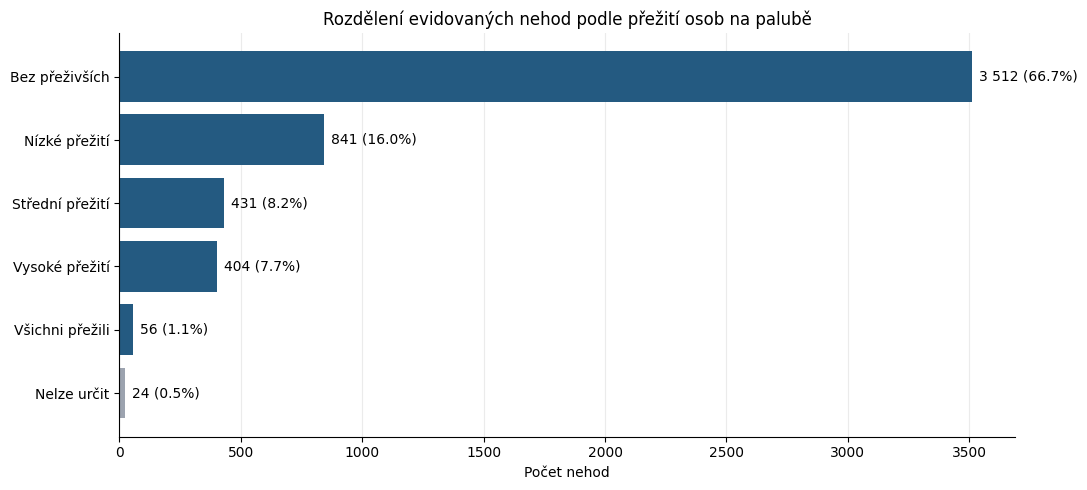

In [38]:
fig, ax = plt.subplots(figsize=(11, 5))

colors = [
    "#245A81" if category != "Nelze určit" else "#9CA3AF"
    for category in survival_summary["Category"]
]

bars = ax.barh(
    survival_summary["Category"].astype(str),
    survival_summary["Accidents"],
    color=colors
)

labels = [
    f"{int(count):,} ({share:.1%})".replace(",", " ")
    for count, share in zip(
        survival_summary["Accidents"],
        survival_summary["Share"]
    )
]

ax.bar_label(bars, labels=labels, padding=5)
ax.invert_yaxis()
ax.set_title("Rozdělení evidovaných nehod podle přežití osob na palubě")
ax.set_xlabel("Počet nehod")
ax.set_xlim(left=0)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(x=0.25)

plt.tight_layout()
plt.show()

### Jaké následky mají evidované nehody?

Největší skupinu tvoří nehody bez přeživších osob na palubě: 3 512 záznamů, tedy 66,7 % celého datasetu. Dalších 841 nehod patří do kategorie nízkého přežití, při kterém přežila méně než polovina osob na palubě.

Dohromady tedy u 4 353 nehod, přibližně 82,6 % všech záznamů, zahynula více než polovina osob na palubě.

Vysoké přežití zaznamenáváme u 404 nehod. U dalších 56 nehod přežili všichni na palubě. Celkem tak u 460 nehod, tedy 8,7 % záznamů, přežilo alespoň 80 % osob na palubě.

U 24 záznamů nelze míru přežití určit kvůli chybějícím údajům nebo nulovému počtu osob na palubě.


## 8. Segmentace podle počtu osob na palubě

Nehody rozdělujeme do čtyř skupin podle počtu osob na palubě: 1–5, 6–20, 21–50 a 51 a více osob.

Záznamy s nulovým počtem osob na palubě a záznamy s neznámým počtem uvádíme samostatně. Do porovnání míry přežití tyto dvě skupiny nevstupují.

Pro každou skupinu počítáme počet nehod a podíl přeživších osob. Míru přežití odvozujeme ze součtu přeživších a součtu osob na palubě.

In [39]:
aboard_order = [
    "1–5 osob",
    "6–20 osob",
    "21–50 osob",
    "51 a více osob",
    "0 osob",
    "Neznámý nebo neplatný počet"
]

# Výchozí skupina pro chybějící či neplatné hodnoty.
df["Aboard_segment"] = "Neznámý nebo neplatný počet"

aboard = df["Aboard"]

# Pro segmentaci přijímáme pouze celé nezáporné počty.
valid_aboard = (
    aboard.notna()
    & aboard.ge(0)
    & aboard.mod(1).eq(0)
)

df.loc[
    valid_aboard & aboard.eq(0),
    "Aboard_segment"
] = "0 osob"

df.loc[
    valid_aboard & aboard.between(1, 5),
    "Aboard_segment"
] = "1–5 osob"

df.loc[
    valid_aboard & aboard.between(6, 20),
    "Aboard_segment"
] = "6–20 osob"

df.loc[
    valid_aboard & aboard.between(21, 50),
    "Aboard_segment"
] = "21–50 osob"

df.loc[
    valid_aboard & aboard.ge(51),
    "Aboard_segment"
] = "51 a více osob"

df["Aboard_segment"] = pd.Categorical(
    df["Aboard_segment"],
    categories=aboard_order,
    ordered=True
)

# Počet všech nehod v jednotlivých skupinách.
segment_counts = (
    df.groupby("Aboard_segment", observed=False)
    .size()
    .rename("Accidents")
)

# Přežití počítáme pouze z platných záznamů.
segment_survival = (
    df.loc[
        df["Valid_survival_rate"] & valid_aboard
    ]
    .groupby("Aboard_segment", observed=True)
    .agg(
        Valid_accidents=("Date", "size"),
        Aboard_valid=("Aboard", "sum"),
        Survivors_valid=("Survivors", "sum")
    )
)

segment_summary = segment_counts.to_frame().join(
    segment_survival
)

segment_summary["Valid_accidents"] = (
    segment_summary["Valid_accidents"]
    .fillna(0)
    .astype(int)
)

segment_summary["Share"] = (
    segment_summary["Accidents"] / len(df)
)

segment_summary["Survival_rate"] = (
    segment_summary["Survivors_valid"]
    / segment_summary["Aboard_valid"]
)

assert segment_summary["Accidents"].sum() == len(df)

display(
    segment_summary.reset_index()
    .rename(columns={
        "Aboard_segment": "Počet osob na palubě",
        "Accidents": "Počet nehod",
        "Valid_accidents": "Nehody pro výpočet přežití",
        "Aboard_valid": "Osoby pro výpočet",
        "Survivors_valid": "Přeživší",
        "Share": "Podíl všech nehod",
        "Survival_rate": "Míra přežití"
    })
    .style.format({
        "Osoby pro výpočet": "{:.0f}",
        "Přeživší": "{:.0f}",
        "Podíl všech nehod": "{:.1%}",
        "Míra přežití": "{:.1%}"
    }, na_rep="Nelze určit")
    .hide(axis="index")
)

Počet osob na palubě,Počet nehod,Nehody pro výpočet přežití,Osoby pro výpočet,Přeživší,Podíl všech nehod,Míra přežití
1–5 osob,1446,1446,4407,387,27.4%,8.8%
6–20 osob,1901,1901,22599,3759,36.1%,16.6%
21–50 osob,1157,1157,36855,7023,22.0%,19.1%
51 a více osob,740,740,80690,28024,14.0%,34.7%
0 osob,2,0,Nelze určit,Nelze určit,0.0%,Nelze určit
Neznámý nebo neplatný počet,22,0,Nelze určit,Nelze určit,0.4%,Nelze určit


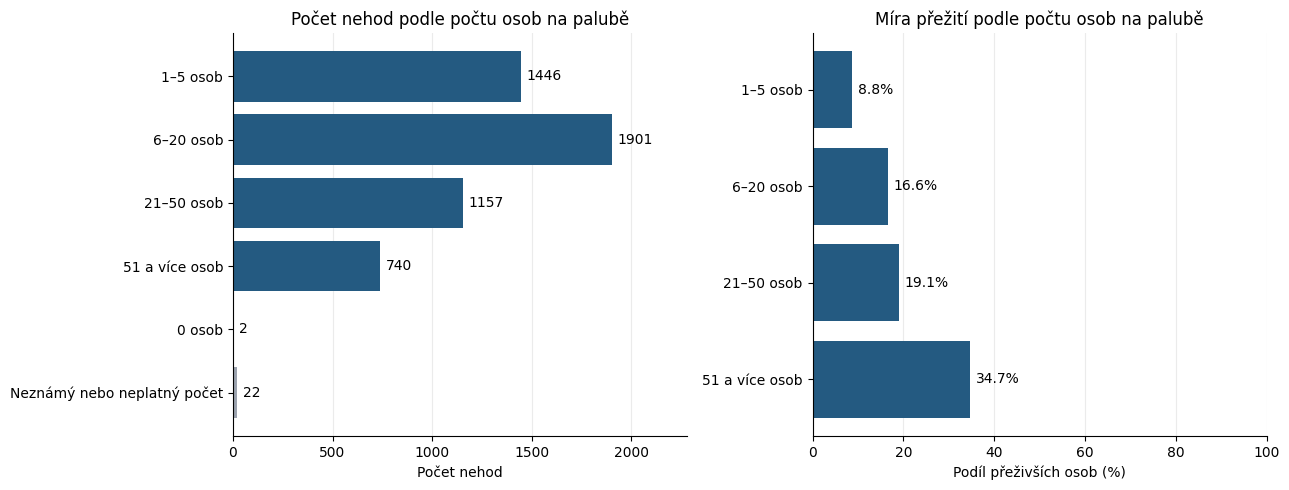

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Počty nehod: všechny skupiny.
count_colors = [
    "#245A81" if segment in aboard_order[:4] else "#9CA3AF"
    for segment in segment_summary.index
]

bars_count = axes[0].barh(
    segment_summary.index.astype(str),
    segment_summary["Accidents"],
    color=count_colors
)

axes[0].invert_yaxis()
axes[0].set_title("Počet nehod podle počtu osob na palubě")
axes[0].set_xlabel("Počet nehod")
axes[0].bar_label(bars_count, padding=4)
axes[0].margins(x=0.2)

# Přežití: pouze čtyři skupiny s kladným počtem osob.
survival_plot = segment_summary.loc[aboard_order[:4]]

bars_survival = axes[1].barh(
    survival_plot.index.astype(str),
    survival_plot["Survival_rate"] * 100,
    color="#245A81"
)

axes[1].invert_yaxis()
axes[1].set_title("Míra přežití podle počtu osob na palubě")
axes[1].set_xlabel("Podíl přeživších osob (%)")
axes[1].set_xlim(0, 100)

axes[1].bar_label(
    bars_survival,
    labels=[
        f"{rate:.1%}" if pd.notna(rate) else "Nelze určit"
        for rate in survival_plot["Survival_rate"]
    ],
    padding=4
)

for ax in axes:
    ax.set_xlim(left=0)
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Četnost nehod podle počtu osob na palubě

Nejpočetnější skupinu tvoří nehody s 6–20 osobami na palubě: 1 901 záznamů. Následují nehody s 1–5 osobami, kterých je 1 446. Dohromady tyto dvě skupiny představují přibližně 63,5 % všech evidovaných nehod.

Nehod s 21–50 osobami je 1 157 a nehod s 51 a více osobami je 740. Dva záznamy uvádějí nulový počet osob na palubě a u 22 záznamů tento údaj chybí.

### Rozdíly v přežití

Souhrnná míra přežití roste napříč zvolenými skupinami: od 8,8 % u nehod s 1–5 osobami přes 16,6 % u skupiny 6–20 osob a 19,1 % u skupiny 21–50 osob až po 34,7 % u skupiny s 51 a více osobami.

### Co z porovnání vyplývá

V dodaném datasetu pozorujeme souvislost mezi vyšším počtem osob na palubě a vyšší souhrnnou mírou přežití. Výsledek však neprokazuje, že vyšší počet osob zvyšuje šanci na přežití.

Skupiny se mohou lišit typem letadla, obdobím provozu, druhem letu nebo okolnostmi nehody. Jejich porovnání proto představuje podnět k dalšímu zkoumání, nikoliv vysvětlení příčiny rozdílu.

## 9. Zajímavosti a anomálie

Vyhledáváme záznamy s nejvyšším počtem obětí na palubě a samostatně s nejvyšším počtem obětí na zemi. Tyto události mohou výrazně ovlivňovat souhrnné výsledky.

Dále zkoumáme dva případy s nulovým počtem osob na palubě a události, při kterých všichni na palubě přežili, ale byly zaznamenány oběti na zemi.

In [41]:
detail_columns = [
    "Date", "Location", "Operator", "Type",
    "Aboard", "Fatalities", "Ground"
]

detail_names = {
    "Date": "Datum",
    "Location": "Místo",
    "Operator": "Provozovatel",
    "Type": "Typ letadla",
    "Aboard": "Osoby na palubě",
    "Fatalities": "Oběti na palubě",
    "Ground": "Oběti na zemi"
}

def show_records(records):
    # Formátování pouze pro zobrazení; data neměníme.
    display(
        records[detail_columns]
        .rename(columns=detail_names)
        .style.format({
            "Datum": lambda value: (
                value.strftime("%d.%m.%Y")
                if pd.notna(value) else "Neznámé"
            ),
            "Osoby na palubě": "{:.0f}",
            "Oběti na palubě": "{:.0f}",
            "Oběti na zemi": "{:.0f}"
        }, na_rep="Neznámé")
        .hide(axis="index")
    )

print("Pět záznamů s nejvyšším počtem obětí na palubě:")
show_records(df.nlargest(5, "Fatalities"))

print("\n")

print("Pět záznamů s nejvyšším počtem obětí na zemi:")
show_records(df.nlargest(5, "Ground"))

Pět záznamů s nejvyšším počtem obětí na palubě:


Datum,Místo,Provozovatel,Typ letadla,Osoby na palubě,Oběti na palubě,Oběti na zemi
27.03.1977,"Tenerife, Canary Islands",Pan American World Airways / KLM,Boeing B-747-121 / Boeing B-747-206B,644,583,0
12.08.1985,"Mt. Osutaka, near Ueno Village, Japan",Japan Air Lines,Boeing B-747-SR46,524,520,0
12.11.1996,"Near Charkhidadri, India",Saudi Arabian Airlines / Kazastan Airlines,Boeing B-747-168B / Ilyushin IL-76TD,349,349,0
03.03.1974,"Near Ermenonville, France",Turkish Airlines (THY),McDonnell Douglas DC-10-10,346,346,0
23.06.1985,"AtlantiOcean, 110 miles West of Ireland",Air India,Boeing B-747-237B,329,329,0




Pět záznamů s nejvyšším počtem obětí na zemi:


Datum,Místo,Provozovatel,Typ letadla,Osoby na palubě,Oběti na palubě,Oběti na zemi
11.09.2001,"New York City, New York",American Airlines,Boeing 767-223ER,92,92,2750
11.09.2001,"New York City, New York",United Air Lines,Boeing B-767-222,65,65,2750
08.01.1996,"Kinshasa, Zaire",African Air,Antonov AN-32B,6,2,225
11.09.2001,"Arlington, Virginia.",American Airlines,Boeing B-757-223,64,64,125
13.10.1976,"Santa Cruz, Bolivia",Lloyd Aéreo Boliviano,Boeing B-707-31,3,3,113


### Události s nejvyššími počty obětí

Nejvyšší počet obětí na palubě uvádí záznam z Tenerife z 27. března 1977: 583 ze 644 osob. Záznam obsahuje dva provozovatele a dva typy letadel. Jeden řádek datasetu tedy nemusí představovat jedno letadlo.

Druhý nejvyšší počet obětí na palubě má záznam Japan Air Lines z 12. srpna 1985: 520 z 524 osob.

###Teroristické útoky z 11. září 2001

Dva záznamy z New Yorku z 11. září 2001 pravděpodobně souvisejí s teroristickými útoky na USA. Jde o lety American Airlines 11 a United Airlines 175, jejichž unesená letadla zasáhla severní a jižní věž World Trade Center.

U obou záznamů je ve sloupci Ground shodně uvedeno 2 750 obětí. V tomto kontextu jde pravděpodobně o opakované uvedení společného počtu obětí na zemi.

In [42]:
zero_aboard = df.loc[df["Aboard"].eq(0)]

survived_with_ground_fatalities = df.loc[
    df["Valid_survival_rate"]
    & df["Survival_rate"].eq(1)
    & df["Ground"].gt(0)
]

print("Záznamy s nulovým počtem osob na palubě:")
show_records(zero_aboard)

for _, row in zero_aboard.iterrows():
    print(
        f"\n{row['Date'].strftime('%d.%m.%Y')} "
        f"— {row['Operator']}"
    )
    print(
        row["Summary"]
        if pd.notna(row["Summary"])
        else "Popis není k dispozici."
    )

print("\n")

print(
    "Všichni na palubě přežili, ale byly evidovány oběti na zemi:",
    len(survived_with_ground_fatalities)
)
show_records(survived_with_ground_fatalities)

Záznamy s nulovým počtem osob na palubě:


Datum,Místo,Provozovatel,Typ letadla,Osoby na palubě,Oběti na palubě,Oběti na zemi
22.09.1981,"Near Babaeski, Turkey",Military - Turkish Air Force,Northrop F-5A,0,0,40
27.03.1986,"Bangui, Central African Republic",Military - French Air Force,Sepecat Jaguar A,0,0,35



22.09.1981 — Military - Turkish Air Force
The fighter crashed into a village after the pilot ejected from the plane.

27.03.1986 — Military - French Air Force
The jet fighter crashed into a school shortly after taking off after experiencing engine failure.


Všichni na palubě přežili, ale byly evidovány oběti na zemi: 19


Datum,Místo,Provozovatel,Typ letadla,Osoby na palubě,Oběti na palubě,Oběti na zemi
25.05.1953,"Amsterdam, Netherlands",KLM Royal Dutch Airlines,Convair CV-240-4,34,0,2
30.06.1959,"Ishikawa City, Ryukyu Island, Okinawa",Military - U.S. Air Force,North American F-100D-25NA,1,0,17
28.02.1963,"Boston, Massachusetts",Eastern Air Lines,Douglas DC-7,26,0,1
17.08.1966,"Near Da Nang, South Vietnam",Military - U.S. Marine Corps,Chance Vought F-8E,1,0,33
22.12.1969,"Near San Diego, California",Military U.S. Navy,LTVF-8J,1,0,14
24.09.1972,"Sacramento, California",Private,F-86 Sabrejet,1,0,22
23.07.1982,"Castaic, California",Western Helicopter,Bell UH-1B Huey Helicopter,1,0,3
01.03.1990,"Near Meerut, India",Military - Indian Air Force,MiG-23,1,0,50
23.03.1994,"Near Fayetteville, North Carolina",Military - U.S. Air Force / Military U.S. Air Force,GD F-16D / Lockheed C-130E,7,0,23
03.02.1998,"Near Cavalese, Trento, Italy",Military - U.S. Marine Corps,Grummand EA-6B,2,0,20


### Nulový počet osob na palubě

U záznamu z 22. září 1981 slovní popis uvádí, že se pilot před pádem letadla katapultoval. To může vysvětlovat zaznamenaný nulový počet osob na palubě při dopadu.

U záznamu z 27. března 1986 popis uvádí pád letadla do školy po poruše motoru, ale nulový počet osob na palubě nevysvětluje.

### Přežití na palubě nepopisuje všechny následky

U 19 záznamů přežili všichni na palubě, přesto byly evidovány oběti na zemi. Kategorie „Všichni přežili“ se tedy vztahuje pouze na osoby na palubě a neznamená událost bez obětí.

### Opakované registrace letadel

Kontrolujeme registrace uvedené u více záznamů. Opakování nemusí znamenat chybu: stejný stroj mohl mít více nehod nebo mohla být registrace znovu použita. Podezřelé případy proto posuzujeme podle data, typu, výrobního čísla a slovního popisu.

In [43]:
# Pomocné názvy pro kontrolu; původní registrace zachováváme.
registration_check = (
    df["Registration"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

registration_counts = registration_check.value_counts()

repeated_registrations = registration_counts[
    registration_counts > 1
]

print("Registrace uvedené u více záznamů:")

display(
    repeated_registrations
    .rename_axis("Registrace")
    .reset_index(name="Počet záznamů")
    .style.hide(axis="index")
)

Registrace uvedené u více záznamů:


Registrace,Počet záznamů
49,3
CF-TCL,2
204,2
19,2
32,2
77,2
PT-EHH,2
82,2
N91303,2
W4026,2


In [44]:
def show_anomaly_records(records):
    columns = [
        "Date", "Location", "Operator", "Type",
        "Registration", "cn/In",
        "Aboard", "Fatalities", "Summary"
    ]

    names = {
        "Date": "Datum",
        "Location": "Místo",
        "Operator": "Provozovatel",
        "Type": "Typ letadla",
        "Registration": "Registrace",
        "cn/In": "Výrobní číslo",
        "Aboard": "Osoby na palubě",
        "Fatalities": "Oběti na palubě",
        "Summary": "Popis události"
    }

    display(
        records.sort_values("Date")[columns]
        .rename(columns=names)
        .style.format({
            "Datum": lambda value: (
                value.strftime("%d.%m.%Y")
                if pd.notna(value) else "Neznámé"
            ),
            "Osoby na palubě": "{:.0f}",
            "Oběti na palubě": "{:.0f}"
        }, na_rep="Neznámé", escape="html")
        .set_properties(
            subset=["Popis události"],
            **{
                "white-space": "normal",
                "min-width": "350px",
                "max-width": "550px",
                "text-align": "left"
            }
        )
        .set_properties(**{"vertical-align": "top"})
        .hide(axis="index")
    )


for registration in ["N864JA", "CCCP-09303"]:
    print(f"\nRegistrace {registration}:")
    show_anomaly_records(
        df.loc[registration_check.eq(registration).fillna(False)]
    )


Registrace N864JA:


Datum,Místo,Provozovatel,Typ letadla,Registrace,Výrobní číslo,Osoby na palubě,Oběti na palubě,Popis události
10.02.1974,AtlantiOcean,North Cay Air - Air Taxi,Brittonnorman BN-2A6,N864JA,Neznámé,2,2,Lost at sea. Never recovered.
02.10.1974,"Off Saint Thomas, U.S. Virgin Islands",North Cay Airways,Britten-Norman BN-2A Islander,N864JA,175,2,2,Crashed into the ocean.



Registrace CCCP-09303:


Datum,Místo,Provozovatel,Typ letadla,Registrace,Výrobní číslo,Osoby na palubě,Oběti na palubě,Popis události
18.07.1970,North AtlantiOcean,Military - Soviet Air Force,Antonov AN-22,CCCP-09303,9340207,23,23,"Disappeared without a trace while en route with a final destination of Peru, 40 minutes after takeoff. The plane was carrying a field hospital to earthquake stricken Peru."
11.11.1992,"Near Tver, Russia",Military - Russian Air Force,Antonov AN-22A,CCCP-09303,53483299,33,33,After climbing to a height of 800 ft. the plane dove into the ground. Improper loading and overloaded.


Registrace **N864JA** se objevuje u dvou nehod v roce 1974. První popis uvádí ztrátu letadla na moři a jeho nenalezení; druhý záznam o několik měsíců později popisuje další pád do oceánu. Podobný provozovatel, typ i stejné počty osob naznačují možnou duplicitu s rozdílným datem nebo chybu v registraci.

Registrace **CCCP-09303** je uvedena u zmizení letadla v roce 1970 a nehody v roce 1992. Výrobní čísla se však liší. Může jít o opětovné použití registrace nebo nesrovnalost v evidenci.

### Dvě události v jednom záznamu

Slovní popis události Pan American World Airways z 28. června 1965 obsahuje také nehodu náhradního letadla vyslaného pro cestující. Zobrazujeme tento konkrétní záznam a jeho úplný popis.

In [45]:
replacement_aircraft_record = df.loc[
    df["Date"].eq(pd.Timestamp("1965-06-28"))
    & df["Operator"].astype("string").str.strip()
        .eq("Pan American World Airways").fillna(False)
]

print("Nouzové přistání a následná nehoda náhradního letadla:")
show_anomaly_records(replacement_aircraft_record)

Nouzové přistání a následná nehoda náhradního letadla:


Datum,Místo,Provozovatel,Typ letadla,Registrace,Výrobní číslo,Osoby na palubě,Oběti na palubě,Popis události
28.06.1965,"San Francisco, California",Pan American World Airways,Boeing B-707-321B,N761PA,18336,153,0,"Just after the aircraft took off from San Francisco International Airport, the No. 4 engine disintegrated tearing off 25 feet of the right wing. An emergency landing was safely made at Travis Air Force Base. A plane was dispatched to pick up the passengers at Travis Air Force Base. While attempting to land, and in plain view of the passengers, the nose gear collapsed. Improper turbine rotor positioning during engine assembly and the use of serviceable worn parts. The aircraft was named 'Clipper Friendship.'"


Po rozpadu motoru a poškození křídla letadlo nouzově přistálo a všech 153 osob přežilo. Pro cestující bylo vysláno náhradní letadlo, kterému se podle popisu při přistání zhroutil příďový podvozek. Jeden řádek datasetu tak zachycuje dvě události různých letadel. Číselné údaje tohoto řádku nelze automaticky přisuzovat oběma událostem.

## 10. Závěr analýzy

Analýza zahrnuje 5 268 záznamů leteckých nehod a dalších událostí z období od září 1908 do června 2009. Níže shrnujeme odpovědi na jednotlivé otázky zadání.


### 1. Trendy v čase

Počet evidovaných nehod v první části sledovaného období obecně rostl, později výrazně kolísal. Nejvyšší počet připadá na rok 1972 se 104 záznamy. Následují roky 1968 s 96 a 1989 s 95 záznamy. Po vrcholu v roce 1972 nepozorujeme souvislý pokles.

Průměrný počet osob na palubě při evidovaných nehodách od přibližně 30. let rostl. Nejvyšší roční průměr dosáhl v roce 1985 přibližně 47 osob.

Míra přežití mezi roky výrazně kolísala. V pozdějších desetiletích se častěji objevovaly vyšší hodnoty, ale vývoj nebyl souvislý. Výrazným výkyvem byl rok 1999 s přežitím 64,8 % osob v použitelných záznamech. Míra úmrtnosti je v téže skupině osob doplňkem míry přežití do 100 %.

Rok 2009 je neúplný, proto jeho počet nehod nelze přímo porovnávat s celými roky.


### 2. Sezónnost

Při porovnání měsíců bez neúplného roku 2009 obsahuje nejvíce nehod prosinec: 517, tedy 9,9 % záznamů. Nejméně jich připadá na květen: 367, tedy 7,0 %.

Z dnů v týdnu má nejvyšší počet čtvrtek s 814 nehodami a nejnižší neděle s 602 nehodami.

Roční období jsme samostatně neporovnávali. Dataset je celosvětový a stejným měsícům odpovídají na severní a jižní polokouli opačná období.


### 3. Provozovatelé a typy letadel

Nejvyšší počet nehod je evidován pod názvy Aeroflot se 179 záznamy a Military - U.S. Air Force se 176 záznamy.

Nejčastěji zastoupeným typem je Douglas DC-3 s 334 nehodami. Následuje de Havilland Canada DHC-6 Twin Otter 300 s 81 nehodami.

Mezi typy s alespoň 20 nehodami použitelnými pro výpočet vykazuje nejvyšší úmrtnost De Havilland DH-4: 96,4 % z 27 nehod. Douglas DC-3 má úmrtnost 78,2 % z 332 použitelných nehod. Nejvyšší počet nehod tedy nemusí odpovídat nejvyššímu podílu obětí.

Žebříčky vycházejí z názvů uvedených ve zdroji, bez slučování variant letadel nebo názvů provozovatelů.


### 4. Klasifikace nehod podle přežití

Nehody jsme rozdělili na případy bez přeživších, s nízkým, středním a vysokým přežitím a případy, kdy přežili všichni na palubě. Nevypočitatelné hodnoty tvoří samostatnou skupinu.

Největší kategorií jsou nehody bez přeživších: 3 512 záznamů, tedy 66,7 % datasetu. Dohromady u 4 353 nehod, přibližně 82,6 % všech záznamů, zahynula více než polovina osob na palubě.

U 460 nehod, tedy 8,7 % záznamů, přežilo alespoň 80 % osob na palubě. U 24 záznamů nelze míru přežití vypočítat.


### 5. Zajímavosti a anomálie

Nejvyšší počet obětí na palubě obsahuje záznam z Tenerife z 27. března 1977: 583 ze 644 osob. Záznam zahrnuje dva provozovatele a dva typy letadel, takže jeden řádek nemusí představovat jedno letadlo.

Dataset zahrnuje také teroristické útoky z 11. září 2001. U dvou letů, které zasáhly World Trade Center, je shodně uvedeno 2 750 obětí na zemi. Hodnota pravděpodobně odkazuje na společné oběti související události. Prostý součet sloupce Ground proto nemusí představovat počet unikátních obětí.

Dva záznamy mají nulový počet osob na palubě. U jednoho popis uvádí katapultáž pilota, u druhého nulový počet nevysvětluje. Hodnoty jsme zachovali a míru přežití nepočítali. U dalších 19 nehod přežili všichni na palubě, přesto byly evidovány oběti na zemi.

Kontrola opakovaných registrací odhalila dva případy hodné ověření. **N864JA** je uvedena u dvou nehod v roce 1974, přestože první popis uvádí ztrátu letadla na moři a jeho nenalezení. Může jít o skrytou duplicitu nebo chybnou registraci. **CCCP-09303** se objevuje u zmizení letadla v roce 1970 a nehody v roce 1992, ale s různými výrobními čísly. Může jít o nové použití registrace nebo nesrovnalost v evidenci. Tyto záznamy jsme bez dalšího ověření neslučovali ani neodstraňovali.

Popis události Pan American World Airways z **28. června 1965** zachycuje nouzové přistání i následnou nehodu náhradního letadla vyslaného pro cestující. Jeden řádek tak může obsahovat více událostí, které nejsou samostatně rozlišeny v číselných sloupcích.


### 6. Vlastní kategorizace a segmentace

Navrhli jsme segmentaci podle počtu osob na palubě: 1–5, 6–20, 21–50 a 51 a více osob. Nulové a neznámé počty jsme ponechali samostatně.

Nejpočetnější skupinou jsou nehody s 6–20 osobami: 1 901 záznamů. Skupiny s 1–20 osobami představují dohromady přibližně 63,5 % datasetu.

Souhrnná míra přežití roste napříč skupinami: 8,8 %, 16,6 %, 19,1 % a 34,7 %. Pozorujeme tedy souvislost mezi vyšším počtem osob na palubě a vyšším podílem přeživších při evidovaných nehodách.


### Omezení

Dataset umožňuje popsat četnost a následky evidovaných událostí. Neobsahuje však údaje o celkovém objemu leteckého provozu ani dokumentaci úplnosti evidence. Z výsledků proto nelze určit pravděpodobnost nehody nebo spolehlivě hodnotit bezpečnost provozovatelů a letadel. Chybějící údaje jsme nenahrazovali nulou ani odhady.

In [46]:
# Kopie připravených dat pro Power BI.
df_export = df.copy()

# Identifikátor řádku pro počítání a dohledání záznamů.
df_export.insert(
    0,
    "Record_ID",
    range(1, len(df_export) + 1)
)

# Pořadí kategorií pro správné řazení v Power BI.
survival_sort = {
    category: position
    for position, category in enumerate(survival_order, start=1)
}

aboard_sort = {
    category: position
    for position, category in enumerate(aboard_order, start=1)
}

df_export["Survival_category_sort"] = (
    df_export["Survival_category"]
    .astype("string")
    .map(survival_sort)
)

df_export["Aboard_segment_sort"] = (
    df_export["Aboard_segment"]
    .astype("string")
    .map(aboard_sort)
)

# Příznak pro stejný výběr dat při analýze sezónnosti.
df_export["Include_seasonality"] = df_export["Year"].le(2008)

# Export: prázdné hodnoty zůstávají prázdné, podíly zůstávají desetinnými čísly.
export_filename = "Plane_Crashes_PowerBI.csv"

df_export.to_csv(
    export_filename,
    index=False,
    sep=";",
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
    na_rep=""
)

print(f"Exportováno {len(df_export)} záznamů.")
print(f"Počet sloupců: {df_export.shape[1]}")

files.download(export_filename)

Exportováno 5268 záznamů.
Počet sloupců: 31


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>